# My chip: the full-loop template

Copy this notebook, rename it, and change the cells marked `# TODO:`. It follows the Quantcore design loop:

**layout → LOM → eigenmode simulations of the components → the same mesh for the FEM runs → extract and analyse → feedback**

As shipped it builds a tiny chip (one Xmon and one λ/4 hanger readout on a feedline, Quantcore PDK) and runs
as far as the LOM without any solver. The FEM sections (3 and 4) export their jobs and load kept results; with
`RUN_FEM = False` nothing is solved. Sections 5 to 7 fill in whatever results exist.

| Section | What you do | Needs |
|---|---|---|
| 0 Setup | set the switches and the targets | nothing |
| 1 Layout | draw the chip a segment at a time, DRC | nothing |
| 2 LOM | simulate the lumped circuit, read it against the targets, tune on it | nothing |
| 3 Eigenmode | export the component job, solve the eigenmode | **simulation PC** |
| 4 FEM on the eigenmode's mesh | Q3D capacitances, driven S21 | **simulation PC** |
| 5 Extract and analyse | FEM values into the LOM, FEM against LOM | kept results from 3 and 4 |
| 6 Feedback | one proposal, a revision, iterate to the targets | nothing (the LOM) |
| 7 Fab | mask export | nothing |

# 0 · Setup and switches

The imports, the output folder, and the **switch cell**. Nothing solves while `RUN_FEM = False`. `LIVE` is read from
`QCC_LIVE`: with KLayout open every change is pushed to its window, with `QCC_LIVE=0` the notebook runs headless.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, FEM and feedback helpers
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.registry import trilayer_junction
from quantcore_circuits.pdk import get_pdk

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
NAME = "my_chip"                                 # TODO: the name of your chip (also the design file's name)
OUT = Path("examples/templates")                 # TODO: where your design JSON and PNG snapshots go (e.g. examples/mine)
OUT.mkdir(parents=True, exist_ok=True)
pdk = get_pdk()

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True: solve again even when kept results match
FEM_FAST = True        # True: fast test settings (minutes, not converged); False: the settings as written (simulation PC)
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback revisions tried by the iterate cell (section 6)

F_Q, F_R = 5.5, 7.0    # TODO: your targets: qubit frequency and readout frequency (GHz)
SIM = {                # solver settings per analysis (the same recipe as tutorial 0)
    "q3d_cmatrix": {"percent_error": 0.5},
    "eigenmode_epr": {"n_modes": 3, "min_frequency": 4.0, "max_delta_f": 0.2, "maximum_passes": 14},
}
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# 1 · Layout, one segment at a time

Each segment adds one kind of thing, then `layout_step` draws a picture and prints what the chip holds so far. Change
one segment, run from there down, and look at the picture: that is the whole habit. The die and the pad rules come
from the PDK, so you do not set them by hand.

## 1.1 · The die and its frame

`Designer(name, box=...)` opens an empty chip; the box is the die in µm. The PDK draws the Quantcore frame on it.

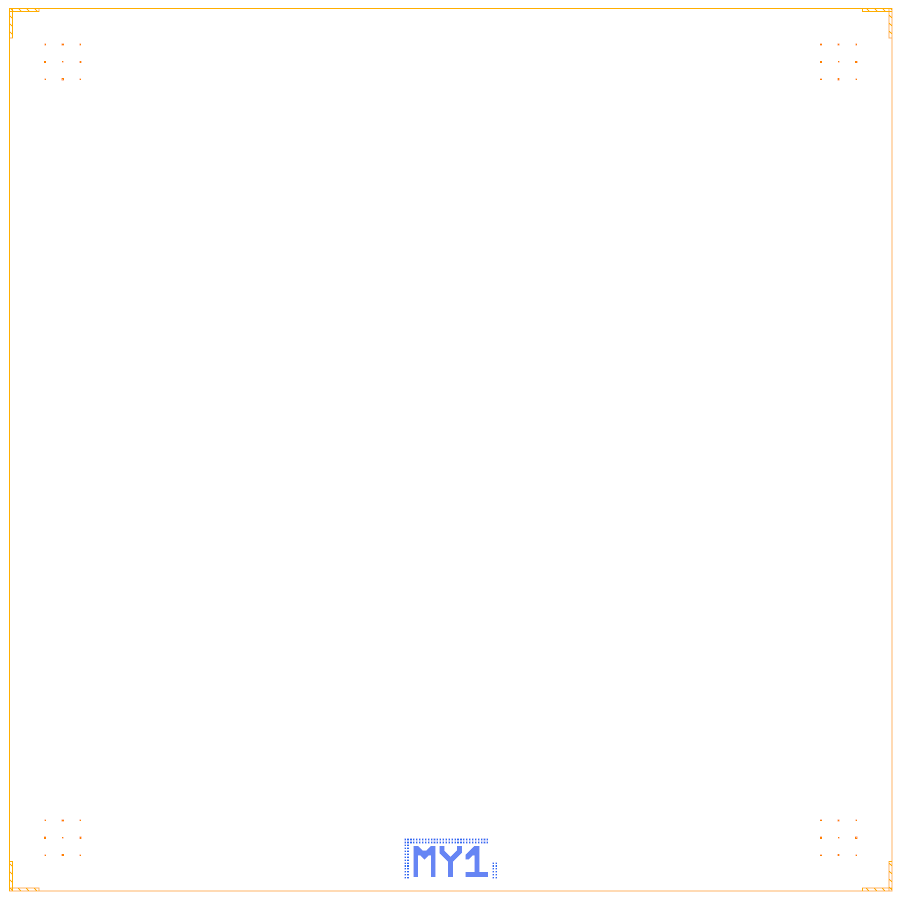

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/templates/my_chip_s1_die.png')

In [4]:
d = Designer(NAME, box=(0, 0, 7500, 7500), chip={"name_chip": "MY1"}, live=LIVE)   # TODO: die size and the chip's short ID
layout_step(d, OUT / f"{NAME}_s1_die.png", size=(900, 900), width=360)

## 1.2 · Bond pads

`edge="auto"` puts the pad at the PDK's 100 µm distance from the die edge, whatever x you ask for.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PAD_W | `BondPad` | w | 100.0 | ✓ |
| PAD_E | `BondPad` | e | 100.0 | ✓ |

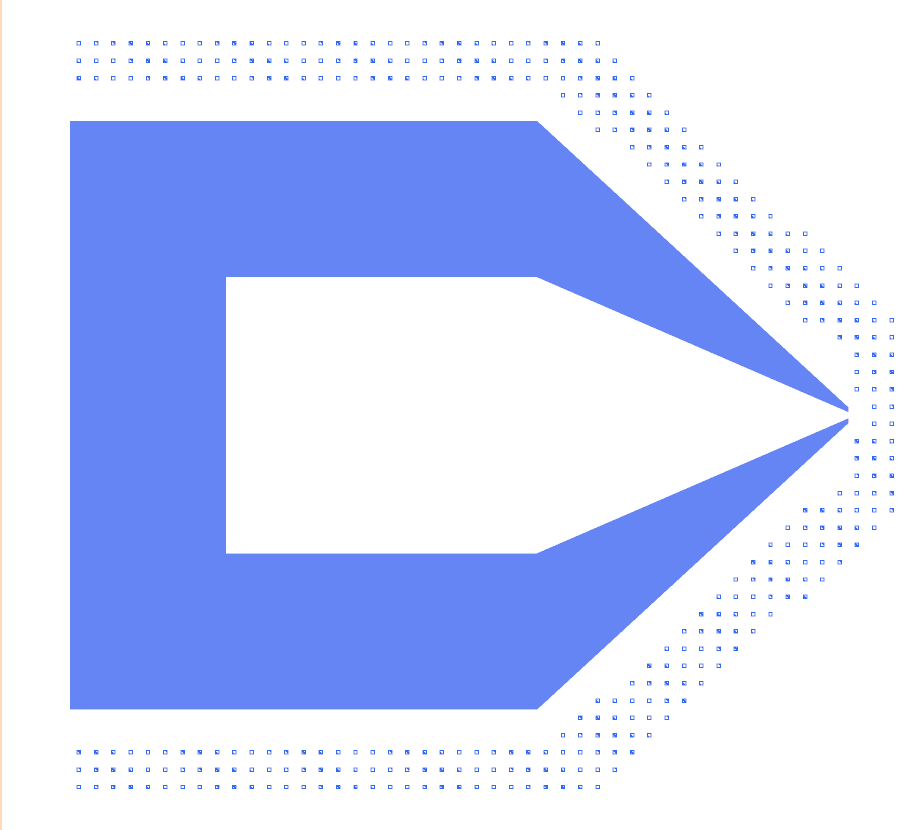

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 2 component(s) `PAD_W`, `PAD_E`.

WindowsPath('examples/templates/my_chip_s2_pads.png')

In [5]:
Y_FL = 3750                                      # TODO: the feedline's height (µm)
with d.batch():
    pw = d.add("PAD_W", "BondPad", at=(1125, Y_FL), rot=270, edge="auto")
    pe = d.add("PAD_E", "BondPad", at=(6375, Y_FL), rot=90, edge="auto")
rebuild(d)
display(Markdown(pads_md(d)))
layout_step(d, OUT / f"{NAME}_s2_pads.png", box=(0, Y_FL - 600, 1300, Y_FL + 600), size=(900, 830), width=360)

## 1.3 · The feedline

A route joins two ports; `FL` is the readout line the resonator hangs from. Routes take `r=` (the bend radius) and
`meander=` (a fixed length).

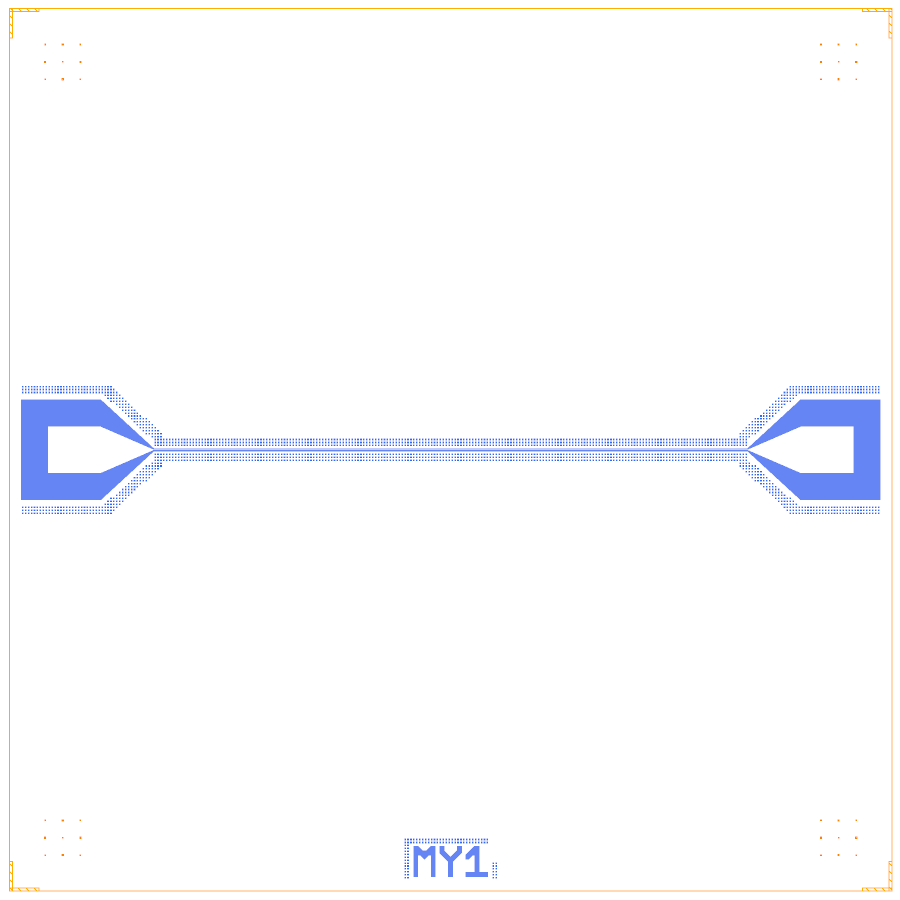

**On the chip so far:** 2 pads · 0 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 route(s) `FL`.

WindowsPath('examples/templates/my_chip_s3_feedline.png')

In [6]:
fl = d.route("FL", pw.a, pe.a)
layout_step(d, OUT / f"{NAME}_s3_feedline.png", size=(900, 900), width=360)

## 1.4 · The qubit

An Xmon with a Quantcore trilayer junction. The junction is first the PDK nominal one, then sized from the target
frequency: `size_junction` takes the LOM's capacitance estimate and gives the L_J (and the R_n it needs, which should
sit inside the PDK window).

C_Σ ≈ 99.2 fF + C_J → L_J 6.92 nH, R_n 46.2 kΩ (in window: True)


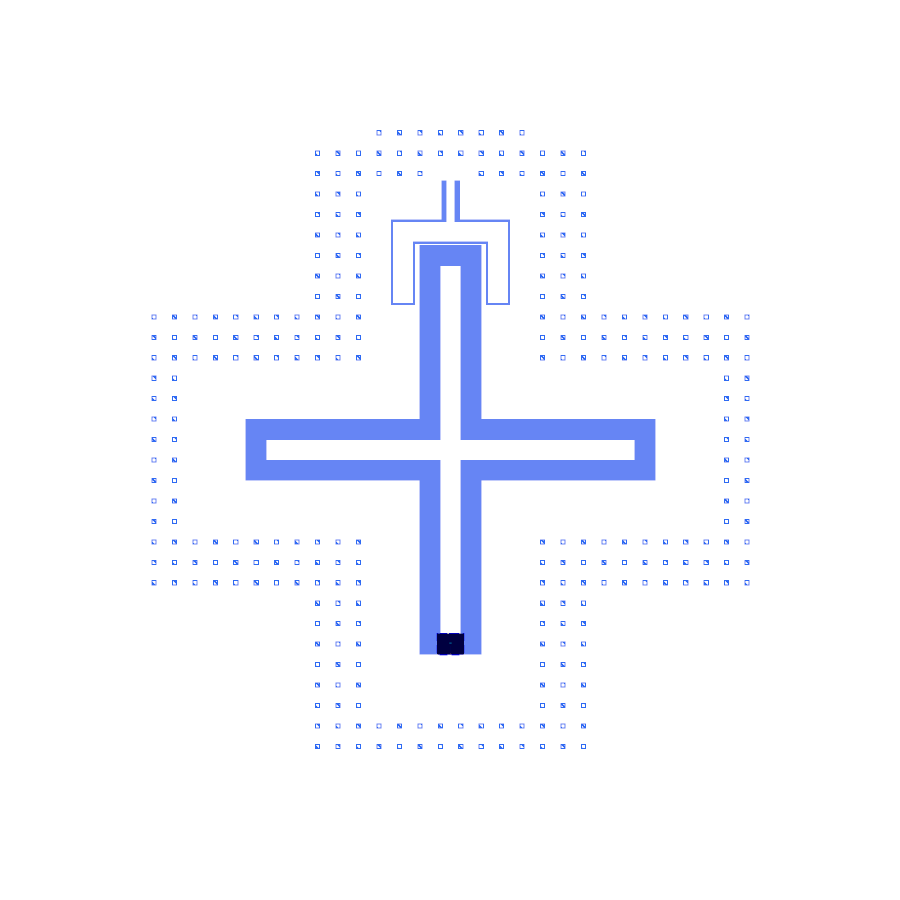

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 1 routes · 0 declared couplings. **This step added** 1 component(s) `Q1`.

WindowsPath('examples/templates/my_chip_s4_qubit.png')

In [7]:
from quantcore_circuits.circuit.bridges import size_junction

params, junction = trilayer_junction("Xmon")                     # the PDK nominal junction (R_n 45 kΩ)
q1 = d.add("Q1", "Xmon", at=(3000, 2100), cross_length=450, arm_width=25, gap=25, claws=["n"],   # TODO: your qubit
           junction=junction, **params)
lb = d.lom()
c_sigma = sum(b.value["estimate"] for n, b in lb.model.branches.items() if n in ("C_Q1", "Cg_Q1_claw_n"))
s = size_junction(F_Q, c_sigma, c_includes_junction=False)
print(f"C_Σ ≈ {c_sigma:.1f} fF + C_J → L_J {s.lj_nH:.2f} nH, R_n {s.rn_kohm:.1f} kΩ (in window: {s.rn_in_window})")
params, junction = trilayer_junction("Xmon", lj_nH=s.lj_nH)
q1.set(junction=junction, **params)
layout_step(d, OUT / f"{NAME}_s4_qubit.png", box=(2450, 1550, 3550, 2650), size=(900, 900), width=360)

## 1.5 · The readout resonator

A λ/4 hanger: it starts at the qubit's claw and ends on a point of the feedline (`fl.hanger(near=..., length=...)` is the
coupled section). The length is the bare λ/4 for the target on the PDK's coplanar waveguide; the claw loads the open end,
so the LOM will say it lands a little low (section 2 fixes that).

R1: 4501 µm


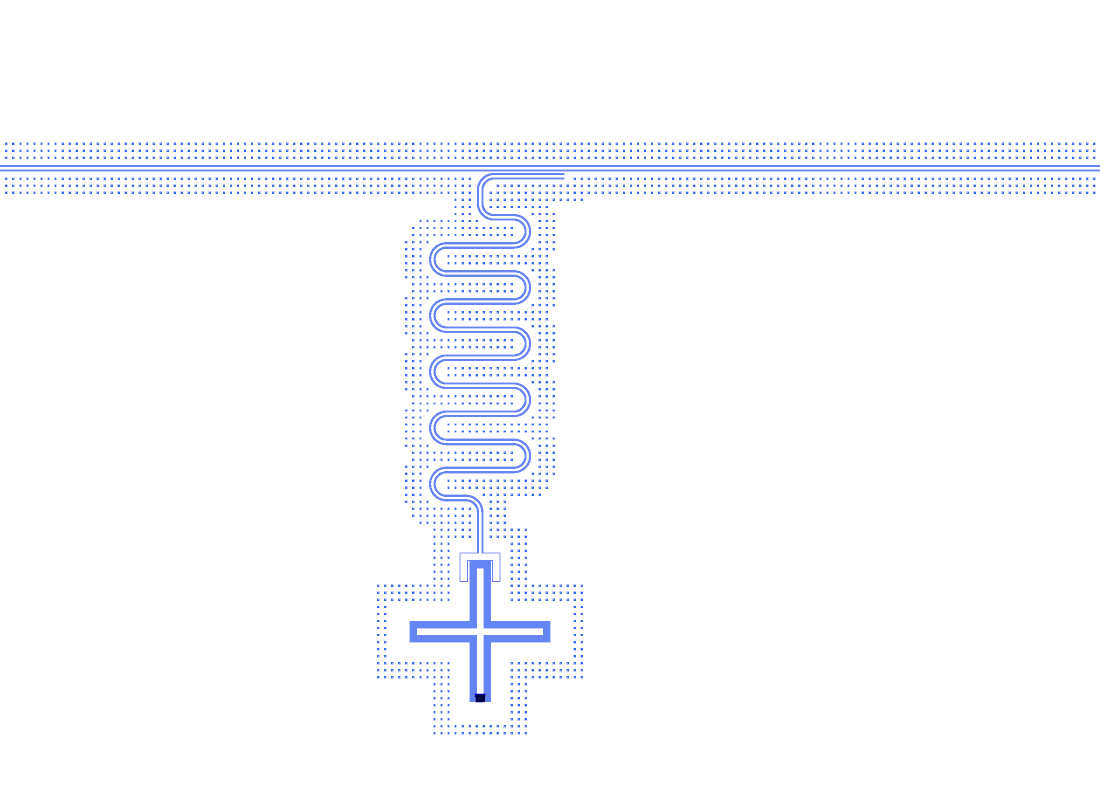

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** 1 route(s) `R1`.

WindowsPath('examples/templates/my_chip_s5_readout.png')

In [8]:
from quantcore_circuits.circuit.bridges import tl_resonator

vp = tl_resonator(4500, pdk.cpw_a, pdk.cpw_b)["vp_m_s"]
L_R1 = vp / (4 * F_R * 1e9) * 1e6                 # bare λ/4 for F_R (µm)
r1 = d.route("R1", q1.claw_n, fl.hanger(near=(3150, Y_FL), length=300, side="right"), meander=L_R1, r=50)   # TODO: coupling length
print(f"R1: {L_R1:.0f} µm")
layout_step(d, OUT / f"{NAME}_s5_readout.png", box=(1500, 1500, 5000, Y_FL + 600), size=(1100, 800), width=420)

## 1.6 · Routing: control lines

This chip has no drive or flux line. **TODO:** add yours here, for example a second `BondPad` and a route from it to a
qubit port (`print(sorted(q1.ports))` lists them). Keep this segment even when empty: the design notebooks use the same
order.

Q1 ports: ['claw_n']


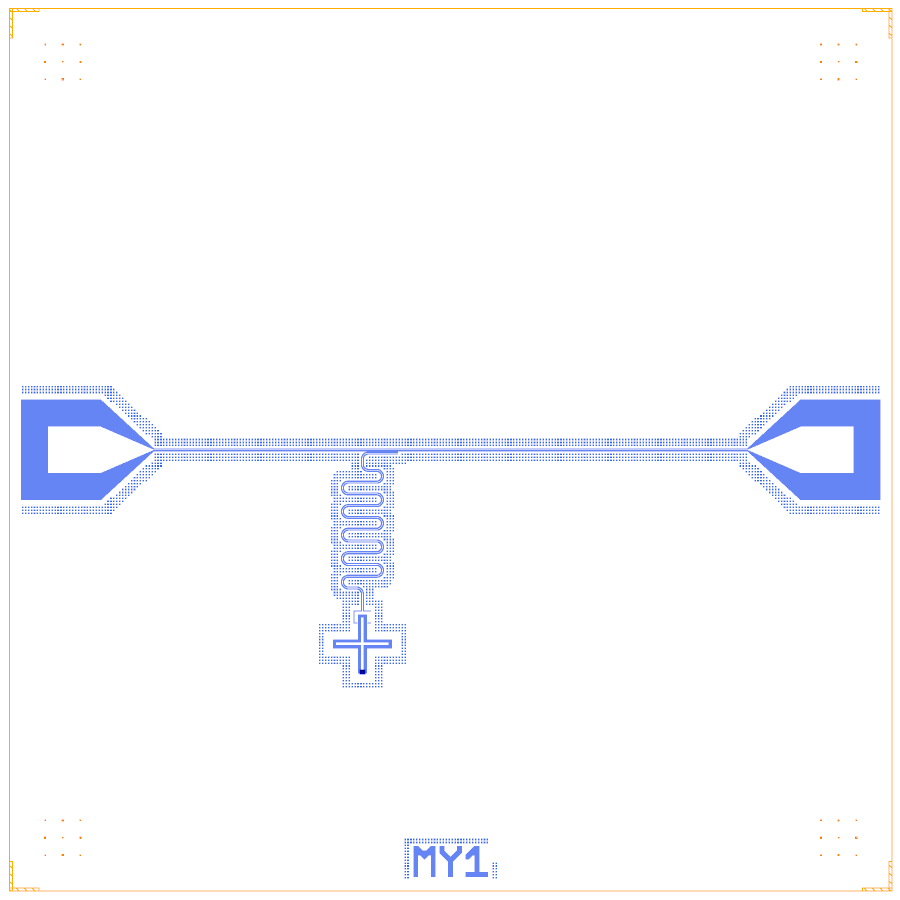

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/templates/my_chip_s6_control.png')

In [9]:
# TODO: control lines, e.g.
# pc = d.add("PAD_D", "BondPad", at=(3750, 6375), rot=180, edge="auto")
# d.route("DRIVE", pc.a, q1.<port>)
print("Q1 ports:", sorted(q1.ports))
layout_step(d, OUT / f"{NAME}_s6_control.png", size=(900, 900), width=360)

## 1.7 · The whole chip: sim group, targets, centring, save

- `d.targets(...)` stores what each quantity should be; the LOM table and the feedback read it.
- `d.sim_subset` declares the **sim group**: the part of the chip a FEM job cuts out (Q1, R1 and 300 µm around them; the
  box cuts the feedline). Sections 3 and 4 solve this group.
- `save_design` writes `my_chip.json` and says whether it changed: the file is the deliverable (`qcc build`, `qcc mask`,
  the KLayout plugin and the dashboard all read it).

content shifted by (0.0, 737.5) µm; sim group: Q1R1


`examples/templates/my_chip.json` written (no earlier file to compare with).

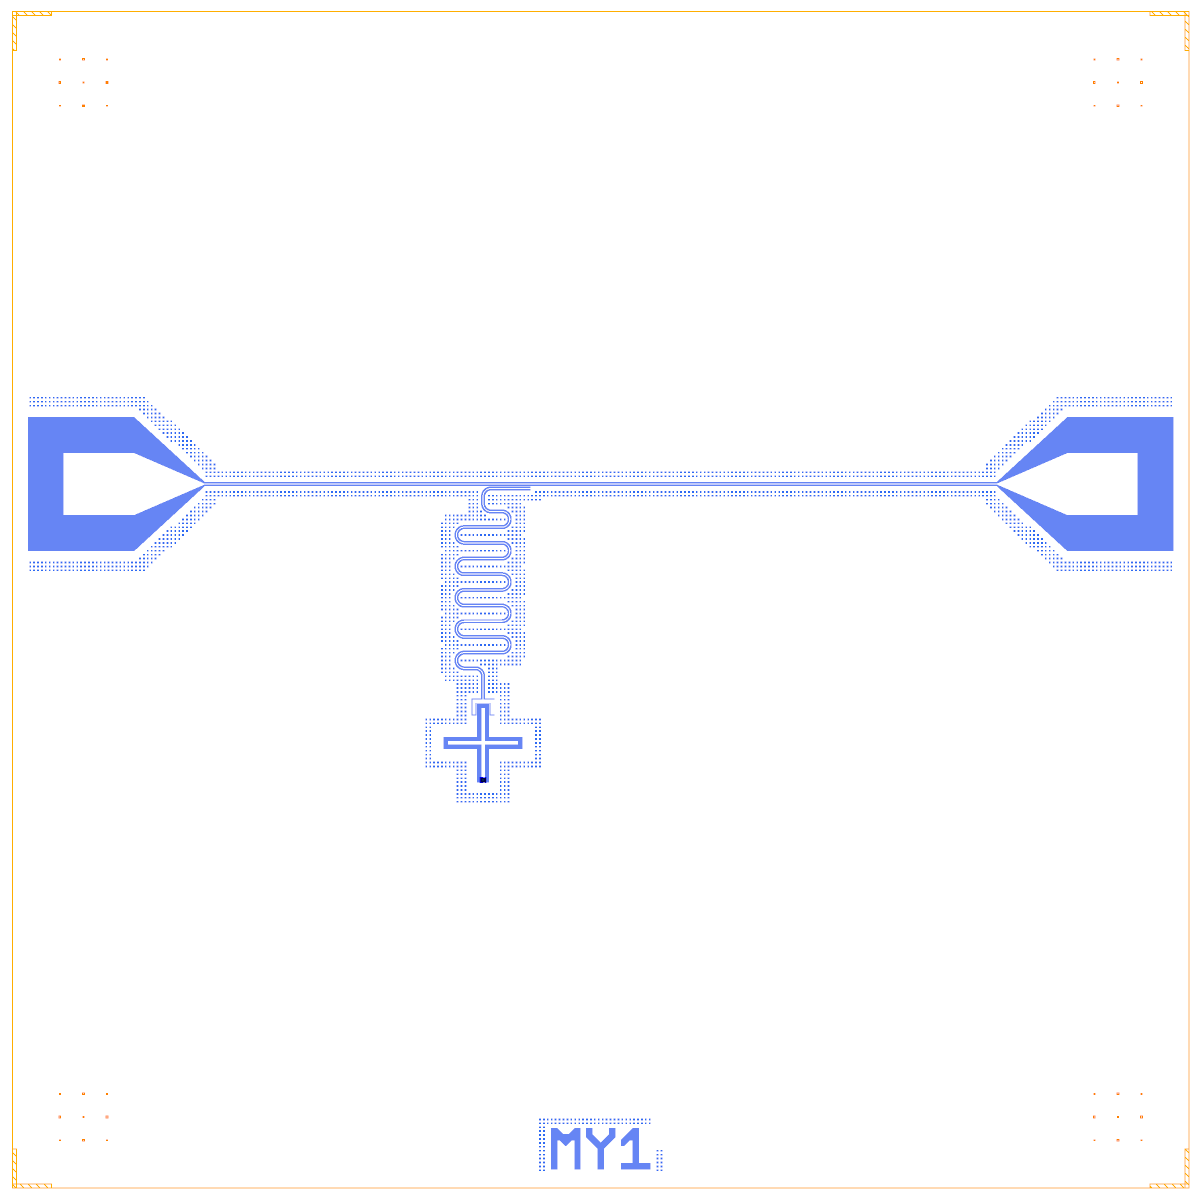

**On the chip so far:** 2 pads · 1 qubits · 0 other components · 2 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('examples/templates/my_chip_s7_chip.png')

In [10]:
d.targets(Q1={"f_q_GHz": F_Q}, R1={"f_GHz": F_R})
GROUP = d.sim_subset("Q1R1", pairs=[("Q1", "R1")], margin_um=300, analyses=list(SIM), settings=SIM)[0]
shift = center_in_die(d)                          # the PDK wants the content centred in the die
rebuild(d)
print("content shifted by", shift, "µm; sim group:", GROUP)
DESIGN, same = save_design(d, OUT / f"{NAME}.json")
display(Markdown(same))
layout_step(d, OUT / f"{NAME}_s7_chip.png", size=(1200, 1200), width=480)

## 1.8 · DRC and netlist

The design rules: connectivity (every port routed), crossings, overlaps, the die frame, and the PDK's margins (pad edge,
keep-outs, centring). Errors must be zero; margins are warnings. The netlist is the lumped circuit the layout turns into.

In [11]:
rep = d.drc()
display(Markdown(drc_md(rep)))
display(Markdown(pdk_report(d)))
lb = d.lom()
show_netlist(lb)

**0 errors · 0 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Quantcore Junction × 1 |
| PDK design warnings | 0 (none) |

**4 nodes · 8 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PAD_W.pad`, `PAD_E.pad` |
| `Q1` | `Q1.island` |
| `Q1.claw_n` | `Q1.claw_n` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PAD_W` | R | `FL` – `gnd` | 50 Ω |
| `Port_PAD_E` | R | `FL` – `gnd` | 50 Ω |
| `C_Q1` | C | `Q1` – `gnd` | 96.1 fF |
| `J_Q1` | JJ | `Q1` – `gnd` | Lj 6.87 nH, Cj 14.7 fF |
| `Cg_Q1_claw_n` | C | `Q1` – `Q1.claw_n` | 3.17 fF |
| `Cc_Q1_claw_n` | C | `Q1.claw_n` – `gnd` | 76.4 fF |
| `R1` | TLres | `Q1.claw_n` – `gnd` | lambda/4, 4501 µm, 7.000 GHz |
| `K_R1` | HANGER | `Q1.claw_n` – `FL` | κ 0.214 MHz (L 300 µm) |

**Unconnected ports:** none

# 2 · LOM: the lumped circuit

The layout turns into a lumped circuit (`d.lom()`); `simulate_groups` solves it (QuCat normal modes, QuTiP dressed
values). It takes seconds, so this is where you iterate. Everything after this section checks or corrects these numbers.

## 2.1 · Simulate

The whole chip is one group here. On a bigger chip, pass one group per qubit and its readout (`simulate_groups(d,
{"Q1+R1": ["Q1", "R1", "FL", ...]})`), as the design notebooks do.

In [12]:
ALL = list(d.data["instances"]) + list(d.data["routes"])      # TODO: or a list of the parts of one sub-circuit
results = simulate_groups(d, {"Q1+R1": ALL})
display(Markdown(groups_md(results)))

| group | qubit | f_q (GHz) | α (MHz) | resonator | f_r (GHz) | κ (MHz) | χ (MHz) |
|---|---|---|---|---|---|---|---|
| Q1+R1 | Q1 | 5.51 | -182.2 | R1 | 6.2518 | 0.135 | -1.13 |

## 2.2 · Plot

Every normal mode of each group (circles are qubits, squares resonators) and the dispersive shift χ of each readout.

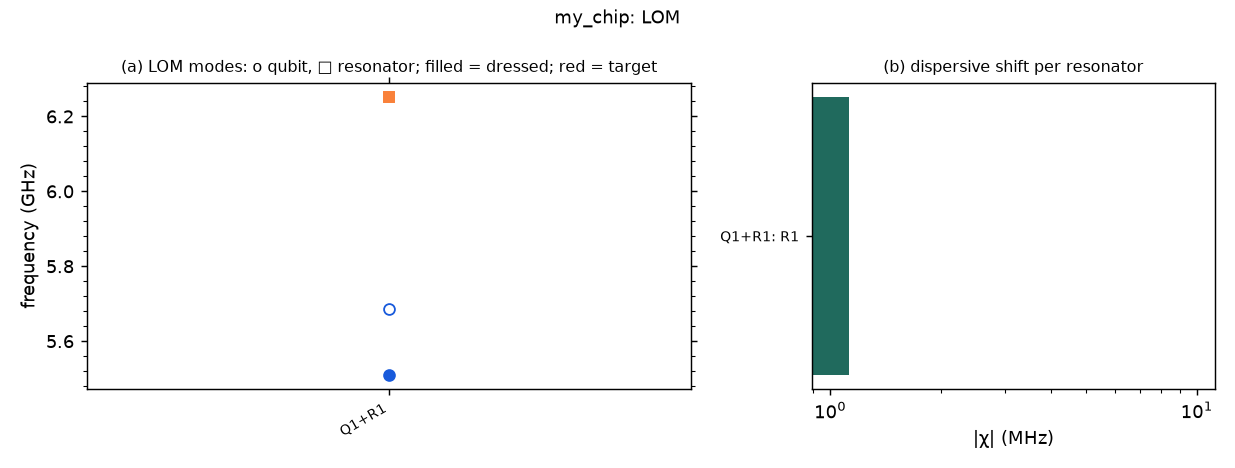

WindowsPath('examples/templates/my_chip_lom.png')

In [13]:
plot_lom(results, OUT / f"{NAME}_lom.png", title=f"{NAME}: LOM")

## 2.3 · Read it against the targets

The table puts each LOM value next to its target. Typical first run: the qubit is close and the readout
lands low (the claw loads the λ/4; here by about 10 %). The next cell corrects the readout by scaling its length (λ/4 ∝ 1/f), one change at
a time, and saves the design again. The save says "The design differs": that is the tuned `R1` length, as it should be.

In [14]:
res = results["Q1+R1"]
display(Markdown(summary_md(res, d.data["targets"])))

| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 5.51 | 5.5 |
| `Q1.alpha_MHz` | -182.18 | – |
| `R1.chi_MHz` | -1.1288 | – |
| `R1.f_GHz` | 6.2518 | 7 |
| `R1.kappa_MHz` | 0.13536 | – |

In [15]:
# TODO: the quantity you tune (here the readout length) and its tolerance
length = L_R1
for step in range(1, 5):
    f_r = res.params["R1.f_GHz"]
    if abs(f_r / F_R - 1) < 0.002:
        break
    length *= f_r / F_R                           # λ/4 ∝ 1/f: scale the drawn length
    r1.set(meander=length)                        # one change → one rebuild
    res = simulate_lom(d.lom(), d.design)
    print(f"step {step}: R1 {length:.0f} µm → f_r {res.params['R1.f_GHz']:.4f} GHz")
DESIGN, same = save_design(d, OUT / f"{NAME}.json")
display(Markdown(summary_md(res, d.data["targets"])))
display(Markdown(same))

step 1: R1 4020 µm → f_r 6.9153 GHz


step 2: R1 3971 µm → f_r 6.9904 GHz


| parameter | LOM (QuTiP) | target |
|---|---|---|
| `Q1.f_q_GHz` | 5.511 | 5.5 |
| `Q1.alpha_MHz` | -182.88 | – |
| `R1.chi_MHz` | -0.43 | – |
| `R1.f_GHz` | 6.9904 | 7 |
| `R1.kappa_MHz` | 0.18728 | – |

**The design differs from the file it replaced** (`examples/templates/my_chip.json`):

- `routes`: changed `R1`

# 3 · Eigenmode simulations of the component

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 3.1 · Export the jobs

`export_sims` cuts each sim group out of the design and writes an AEDT job folder (`build/jobs/...`): the geometry, the
junction as a lumped L_J ‖ C_J sheet, the ports and the solver settings. The eigenmode job comes first: its mesh settings
seed the driven run in section 4. Kept results go in `<your folder>/fem/`.

In [ ]:
FEM_FAST = fem_fast(FEM_FAST)                    # the switch from the top: fast test settings, or as written
KEEP = fem_keep_dir(DESIGN)                      # examples/templates/fem/: solved results are kept here
jobs_eig = export_sims(DESIGN, [GROUP], analysis="eigenmode_epr")
jobs_q3d = export_sims(DESIGN, [GROUP], analysis="q3d_cmatrix")
display(Markdown(jobs_md(jobs_eig) + "\n" + jobs_md(jobs_q3d).split("\n", 2)[2]))

## 3.2 · Solve the eigenmode job

**Simulation PC.** With `RUN_FEM = False` this loads kept results from `fem/` or returns `None` for the job. The
convergence table shows the adaptive passes and the mesh that was reached; the plot shows the modes (the LOM's
frequencies as dashed lines).

In [ ]:
keep_eig = fem_stage(jobs_eig, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · eigenmode": k for g, k in keep_eig.items()})))
lom_f = {"Q1": res.params.get("Q1.f_q_GHz"), "R1": res.params.get("R1.f_GHz")}
plot_eigenmodes(keep_eig, OUT / f"{NAME}_eigenmodes.png", lom=lom_f)
for g, k in keep_eig.items():
    if k:
        display(Markdown(eigen_md(k)))

# 4 · FEM on the eigenmode's mesh

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

## 4.1 · Q3D capacitance matrix

The capacitances of the same group, measured instead of estimated. They fill the LOM in section 5.

In [ ]:
keep_q3d = fem_stage(jobs_q3d, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
display(Markdown(convergence_md({f"{g} · q3d": k for g, k in keep_q3d.items()})))
for g, k in keep_q3d.items():
    if k:
        display(Markdown(cmatrix_md(k)))

## 4.2 · Driven run (S21) on the eigenmode's settings

The library cannot hand a solved eigenmode mesh to a driven setup, so `driven_from_eigenmode` uses the next best thing:
the same group and box, the eigenmode job's mesh seeds, the adaptive frequency at the eigenmode's resonator mode, and a
fast sweep around it. The notch of S21 gives the resonator's frequency and κ.

In [ ]:
jobs_drv = driven_from_eigenmode(DESIGN, GROUP, jobs_eig[GROUP][0], keep_eig[GROUP], f_guess=res.params.get("R1.f_GHz"))
keep_drv = fem_stage(jobs_drv, RUN_FEM, KEEP, force=RESOLVE, aedt=AEDT_MODE)
if keep_drv[GROUP]:
    display(Markdown(driven_md(keep_drv[GROUP])))

# 5 · Extract and analyse

Bring the FEM numbers into the LOM's terms and compare. Two ways: **fill** the LOM with the Q3D capacitances (the circuit
is the same, the C values are measured), and read f_q, α, f_r, χ, κ straight from the eigenmode run (pyEPR). The cells
print one line instead when nothing is solved.

## 5.1 · Fill the LOM, and the FEM values

`fill(model, design, job)` replaces the estimated capacitances of the simulated components with the Q3D values;
`epr_values` reads the eigenmode job as `Q1.f_q_GHz`, `R1.chi_MHz`, ... and `driven_values` the S21 notch.

In [ ]:
from quantcore_circuits.circuit.fill import fill
from quantcore_circuits.lom.simulate import simulate

KEYS = ["Q1.f_q_GHz", "Q1.alpha_MHz", "R1.f_GHz", "R1.chi_MHz", "R1.kappa_MHz"]
est = res.params                                   # the LOM on its estimates (section 2)
fem = {}                                           # {source: {key: value}}
if keep_q3d[GROUP]:
    fem["LOM on the Q3D C-matrix"] = simulate(fill(d.lom().model, DESIGN, keep_q3d[GROUP]), max_modes=2).params
if keep_eig[GROUP]:
    fem["eigenmode + pyEPR"] = epr_values(keep_eig[GROUP], {"Q1": "R1"}, {"R1": est["R1.f_GHz"]})
if keep_drv[GROUP]:
    fem["driven S21 notch"] = driven_values(keep_drv[GROUP], "R1", est["R1.f_GHz"])

## 5.2 · FEM against LOM

One row per quantity and source, with the difference in %. This is the number that tells you how far to trust section 2.

In [ ]:
rows = [(k, est.get(k), vals.get(k), src) for src, vals in fem.items() for k in KEYS if k in vals]
if rows:
    display(Markdown(fem_vs_lom_md(rows)))
else:
    print("No FEM results yet: with RUN_FEM = True (simulation PC) or kept results in fem/, this table puts f_q, alpha, "
          "f_r, chi and kappa of the LOM next to the LOM on the Q3D C-matrix, the eigenmode and the S21 notch.")

## 5.3 — Plots and lumped EPR

The convergence of the jobs side by side, the S21 notch fit, and the energy participation of the junction in each
mode. Junctions are lumped, so there are no field integrals: the participation comes from the LOM (free) or from the
eigenmode's `L_J` sensitivity (`method="eigenmode-dL"`, one extra solve per junction), and from pyEPR's own `p_mj`
when the job recorded it (`method="energy"`). The helpers are in `_common` (`plot_convergence`, `plot_s21_fit`,
`plot_epr`, `epr_lumped`); the method is in `docs/library/epr.md`.

In [ ]:
solved = {f"{g} · {a}": k for a, ks in (("q3d", keep_q3d), ("eigenmode", keep_eig)) for g, k in ks.items() if k}
if solved:
    plot_convergence(solved, OUT / f"{NAME}_convergence.png")   # criterion per pass and per mesh size, against its target
if keep_drv[GROUP]:
    plot_s21_fit(keep_drv[GROUP], OUT / f"{NAME}_s21_fit.png")  # |S21| notch fit (the kept results hold the fit, not the trace)
if not solved and not keep_drv[GROUP]:
    print("No FEM results yet: the convergence plots need a solved job.")

In [ ]:
epr_lom = epr_lumped("lom", lom=res)                     # LOM route: participations from the normal modes, no FEM
if keep_eig[GROUP]:
    try:                                                 # pyEPR's p_mj, if this eigenmode job recorded it
        epr_job = epr_lumped("energy", keep=keep_eig[GROUP], plot=False, compare=epr_lom)
    except (KeyError, ValueError, StopIteration):
        print("this eigenmode job has no pyEPR participations; solve one junction-L_J step for method='eigenmode-dL'")
    # eigenmode L_J sensitivity (simulation PC: one extra solve per junction and step, same mesh):
    # epr_dl = epr_lumped("eigenmode-dL", keep=keep_eig[GROUP], lj_nH=[LJ], perturbed={"Q1": [(0.98 * LJ, keep_m2), (1.02 * LJ, keep_p2)]})

# 6 · Feedback

The loop that makes the chip match its targets. `loop.analyse` runs every estimator it has on the circuit (the LOM, the
FEM values you pass in) and picks one value per quantity (the consensus), with the residual against the target in
tolerances. `loop.feedback` turns the residuals into new knob values (readout length, L_J, claw) through a surrogate
anchored on that point, and writes a **new revision** (`build/<name>/revisions/rev1.json`), built and checked.

`target_copy` puts the targets into a copy of the design, so `my_chip.json` stays the deliverable.

## 6.1 · Analyse and propose

In [ ]:
from quantcore_circuits import loop
from quantcore_circuits.assembly.drc import check

TARGETS = {"Q1": {"f_q_GHz": F_Q}, "R1": {"f_GHz": F_R}}      # TODO: your targets; tolerances are the LOM defaults
DESIGN_T = target_copy(DESIGN, TARGETS)
BOUNDS = pdk_lj_bounds(DESIGN)                                  # L_J of the PDK R_n window
FILL = [k for k in keep_q3d.values() if k] or None              # kept Q3D results fill the circuit; None: the estimates
an0 = loop.analyse(str(DESIGN_T), FILL, readout=False)
display(Markdown(consensus_md(an0, only_targets=True)))
prop, rev1, rev1_build = loop.feedback(an0, design_source=str(DESIGN_T), bounds=BOUNDS)
display(Markdown(proposal_md(prop)))
now = {r.param: r.chosen for r in an0.rows}
display(Markdown(before_after_md({k: now.get(k) for k in prop.residuals}, {k: prop.predicted[k] for k in prop.residuals})))
print("revision 1:", rev1, "· DRC:", "clean" if check(rev1_build).ok else "ERRORS")

## 6.2 · Iterate to the target

The same step repeated until every target is inside its tolerance or `MAX_ITER` revisions were made. Without FEM each
revision is judged on the LOM. With `RUN_FEM = True` pass `solve=` a function that exports and solves the revision's
jobs (as the design notebooks' `solve_rev` does), and each revision is judged on FEM values.

In [ ]:
history, last, an_last = iterate_to_target(DESIGN_T, FILL, max_iter=MAX_ITER, bounds=BOUNDS, an=an0)
display(Markdown(history_md(history)))
plot_iterations(history, OUT / f"{NAME}_iterate.png")
print("last design:", last, "· on target:", history[-1]["on_target"])

## 6.3 · Adopt a revision

A revision is only a file until you decide. To make one your design, copy it over `my_chip.json` (git keeps the old one),
reopen it (`Designer.load`, or the KLayout plugin), and run again from section 1 with the new knob values written into
your cells. One change at a time, then look at the picture.

In [ ]:
ADOPT = False                                    # TODO: True to copy the last revision over the design file
if ADOPT:
    import shutil
    shutil.copy(last, DESIGN)
    print("design file replaced by", last)
else:
    print("not adopted:", last)

# 7 · Fab: the mask

`export_fab` writes the mask file: the PDK's fab layers, the cheese band, rounded corners. The cell lists each layer
with its polygon count; the pictures are a close look at the qubit on the mask.

In [ ]:
display(Markdown(fab_layers_md(d, Path("build") / f"{NAME}_fab.oas", cheese=True, rounding=True)))   # TODO: cheese / rounding
QX, QY = d.data["instances"]["Q1"]["place"]["at"]
show_snapshot(d, OUT / f"{NAME}.png", size=(1500, 1500), width=480)
snap_file(Path("build") / f"{NAME}_fab.oas", OUT / f"{NAME}_fab_q1.png", box=(QX - 650, QY - 650, QX + 650, QY + 650),
          size=(1300, 1300), width=420)

## What to do next

- Add a second qubit: copy 1.4 and 1.5, add a coupling (`d.couple(...)`) and a second target, and simulate per pair.
- Keep `RUN_FEM = False` on a small PC and carry the `fem/` folder from the simulation PC.
- Read the guide: `docs/tutorials/write-your-own-notebook.md`.